In [1]:
import math
import numpy
import matplotlib.pyplot as pyplot
%matplotlib inline





In [ ]:
'''
class Value():

    def __init__(self,data,label='' , _variables ={}, _op =''):
        self.data = data
        self._var =set(_variables)
        self._op = _op
        self.label = label

    def __repr__(self):
       return f'Value(data = {self.data})'

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other) , '+')
        return out
    def __mul__(self,other):
        out = Value(self.data * other.data,  (self,other), '*')
        return out

'''



In [5]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


In [6]:
from graphviz import Digraph

In [7]:
def Trace(root):
    nodes,edges= set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for _prev in v._prev:
                edges.add((_prev,v))
                build(_prev)
    build(root)
    return nodes, edges





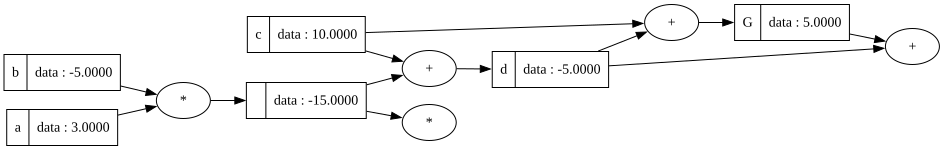

In [13]:
def draw_graph(root):
    nodes, edges = Trace(root)
    dot= Digraph(format ='svg', graph_attr= {'rankdir':'LR'})
    for n in nodes:
        uid=str(id(n))
        dot.node(name=uid, label="{%s | data : %.4f}" % (n.label, n.data), shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label =n._op)
            dot.edge(tail_name = uid, head_name= n._op)
            dot.edge(uid+n._op,uid)
    for n1, n2 in edges:
            dot.edge(str(id(n1)), str(id(n2))+n2._op)
    return dot

class Value():

    def __init__(self,data,label='' , _prev =(), _op =''):
        self.data = data
        self._prev =set(_prev)
        self._op = _op
        self.label = label

    def __repr__(self):
       return f'Value(data = {self.data})'

    def __add__(self, other):
        out = Value(self.data + other.data, _prev = (self, other) , _op='+')
        return out
    def __mul__(self,other):
        out = Value(self.data * other.data,  _prev = (self,other), _op= '*')
        return out
   # def __trueediv__(self,other):
    #    (self.data / other.data, (self,other), '/')






    
        
a = Value(3.0)
a.label = 'a'
b=Value(-5.0)
b.label ='b'
c =Value (10.0)
c.label = 'c'
d = a * b + c
d.label ='d'
#e= d + c
#e.label ='e' 
#f = e*d
#f.label ='f'
G = d + c
G.label ='G'
draw_graph(G)



In [9]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Users\humai\anaconda3\Library\bin"